In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
file_path="C:\\Users\\user\\Downloads\\datasets\\Visadataset.csv"
visa_df=pd.read_csv(file_path)
visa_df.head()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV01,Asia,High School,N,N,14513,2007,West,592.2029,Hour,Y,Denied
1,EZYV02,Asia,Master's,Y,N,2412,2002,Northeast,83425.6500,Year,Y,Certified
2,EZYV03,Asia,Bachelor's,N,Y,44444,2008,West,122996.8600,Year,Y,Denied
3,EZYV04,Asia,Bachelor's,N,N,98,1897,West,83434.0300,Year,Y,Denied
4,EZYV05,Africa,Master's,Y,N,1082,2005,South,149907.3900,Year,Y,Certified


**bi-variant analysis**

In [3]:
visa_df["continent"].value_counts()

continent
Asia             16861
Europe            3732
North America     3292
South America      852
Africa             551
Oceania            192
Name: count, dtype: int64

In [4]:
visa_df["case_status"].value_counts()

case_status
Certified    17018
Denied        8462
Name: count, dtype: int64

In [ ]:
#q: out all asia contint applicant how many got cerified visa

In [44]:
continents=visa_df["continent"].unique()

In [45]:
visa_df[(visa_df["continent"]=="Asia") & (visa_df["case_status"]=="Certified")]

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
1,EZYV02,Asia,Master's,Y,N,2412,2002,Northeast,83425.65,Year,Y,Certified
5,EZYV06,Asia,Master's,Y,N,2339,2012,South,78252.14,Year,Y,Certified
6,EZYV07,Asia,Bachelor's,N,N,4985,1994,South,53635.39,Year,Y,Certified
8,EZYV09,Asia,Bachelor's,N,N,4810,2012,Midwest,74362.19,Year,Y,Certified
10,EZYV11,Asia,Master's,N,N,2465,2004,Midwest,83588.56,Year,Y,Certified
...,...,...,...,...,...,...,...,...,...,...,...,...
25475,EZYV25476,Asia,Bachelor's,Y,Y,2601,2008,South,77092.57,Year,Y,Certified
25476,EZYV25477,Asia,High School,Y,N,3274,2006,Northeast,279174.79,Year,Y,Certified
25477,EZYV25478,Asia,Master's,Y,N,1121,1910,South,146298.85,Year,N,Certified
25478,EZYV25479,Asia,Master's,Y,Y,1918,1887,West,86154.77,Year,Y,Certified


In [49]:
certified=[]
denied=[]
for i in continents:
    certified.append(len(visa_df[(visa_df["continent"]==i) & (visa_df["case_status"]=="Certified")]))
    denied.append(len(visa_df[(visa_df["continent"]==i) & (visa_df["case_status"]=="Denied")]))
  

In [50]:
certified

[11012, 397, 2037, 2957, 493, 122]

In [52]:
pd.DataFrame(zip(continents,certified,denied),columns=["continents","Certified","Denied"])

,continents,Certified,Denied
0,Asia,11012,5849
1,Africa,397,154
2,North America,2037,1255
3,Europe,2957,775
4,South America,493,359
5,Oceania,122,70


pd.crosstab() 

In [63]:
#builtin method
col1=visa_df["continent"]
col2=visa_df["case_status"]

res=pd.crosstab(col1,col2)
res

case_status,Certified,Denied
continent,,
Africa,397,154
Asia,11012,5849
Europe,2957,775
North America,2037,1255
Oceania,122,70
South America,493,359


<Axes: xlabel='continent'>

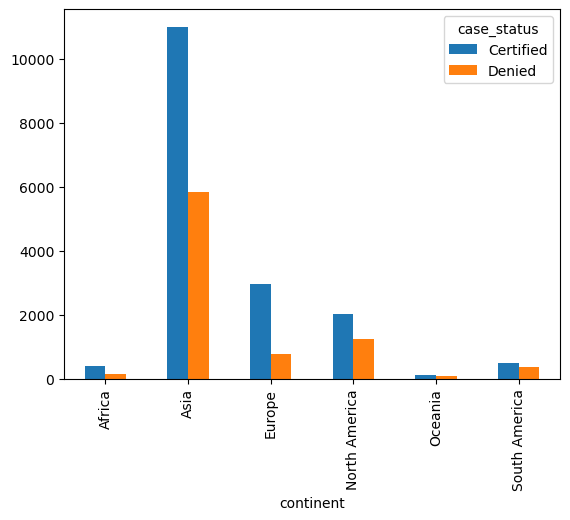

In [67]:
res.plot(kind="bar")

In [75]:
#continet
#education
#case_status
col1=visa_df["continent"] #index
col2=visa_df["education_of_employee"]
col3=visa_df["case_status"]
col=[col2,col3]
res2=pd.crosstab(col1,col)
res2

education_of_employee Bachelor's        Doctorate        High School         \
case_status            Certified Denied Certified Denied   Certified Denied   
continent                                                                     
Africa                        81     62        43     11          23     43   
Asia                        4407   2761       780    143         676   1614   
Europe                      1040    259       788     58         162    328   
North America                641    584       207     51         210    191   
Oceania                       38     28        19      3          19     17   
South America                160    173        75     14          74     63   

education_of_employee  Master's         
case_status           Certified Denied  
continent                               
Africa                      250     38  
Asia                       5149   1331  
Europe                      967    130  
North America               979    429  
Oceania                      46     22  
South America               184    109

<Axes: xlabel='continent'>

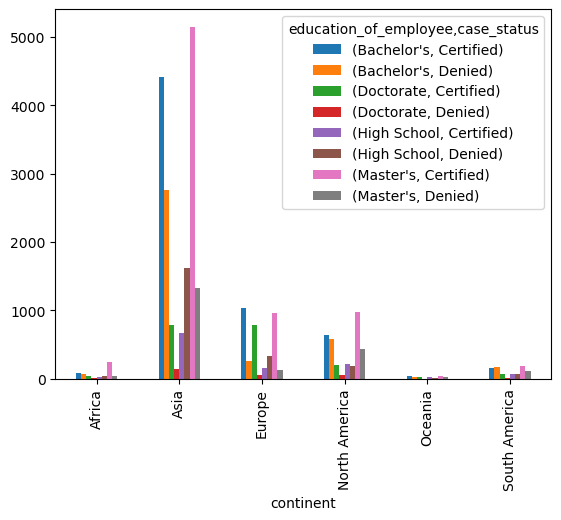

In [76]:
res2.plot(kind="bar")

**Numerical vs numerical**
- till now we have use catrgoriacl anlaysis

- plt.scatter()
- scatter plot is only for numerical data
- scatter plots provides an idea both variables are releted or not
- positive,negative or no relation
- positive releation means increase in curve
- negative means decrese in curve
- no releton means no increase no decrese

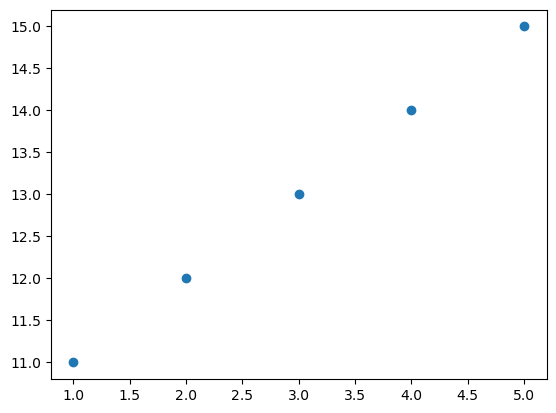

In [77]:
x=[1,2,3,4,5]
y=[11,12,13,14,15]
plt.scatter(x,y)


**parabola**

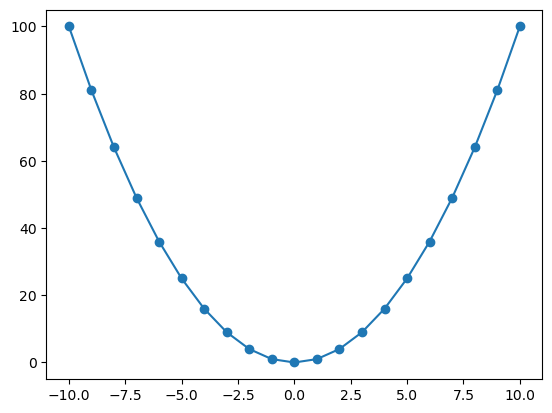

In [87]:
x=[i for i in range(-10,11,1)] #x[-10,10]
y=[i*i for i in x] #y=[100,100]
plt.scatter(x,y)     # only dots
plt.plot(x,y)      #joins the dots create a parabola

In [104]:
n=[]
dtypes=dict(visa_df.dtypes)
for i in dtypes:
    if dtypes[i]!="O":
        n.append(i)
n
        

['no_of_employees', 'yr_of_estab', 'prevailing_wage']

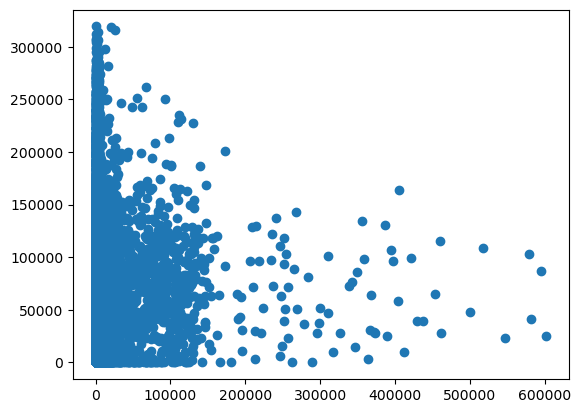

In [106]:
x=visa_df["no_of_employees"]
y=visa_df["prevailing_wage"]
plt.scatter(x,y) #no reletion

In [108]:
n

['no_of_employees', 'yr_of_estab', 'prevailing_wage']

**Co-variance:reletion between variables**

In [ ]:
there are 3 numerical columns
co-variance matrix:

                 no_emp           yr_estb           wage
no_emp             var             cov               cov

yr_esb             cov             var               cov

wage               cov             cov               var

    

In [ ]:
**Co-relation coefficent** 
- denoted by r
- how much reletion between varible
- r ranges from -1 to 1
    positive relation ranges  (0,1]  [] means include 1 include 0 not
    negative relation ranges  (-1,0]
    noo relatioon means      ~0
    

<img src="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcQYm-TxUhGUfIGEmMU7fk1i5OYzM6MR0VHZTQrH8ef0U9szfvKVVlIpu3UJ&amp;s=10" jsaction="" class="sFlh5c FyHeAf uT7N3d" style="max-width: 504px; width: 390.698px; height: 100px; margin: 0px;" alt="Correlation - Definition, Formula, Example, How to Find" jsname="kn3ccd">

**corr method**
- provide covarince matrix

In [114]:
pd.__version__

'2.3.3'

In [111]:
visa_df.corr(numeric_only=True)      

,no_of_employees,yr_of_estab,prevailing_wage
no_of_employees,1.000000,-0.017770,-0.009523
yr_of_estab,-0.017770,1.000000,0.012342
prevailing_wage,-0.009523,0.012342,1.000000


In [ ]:
no reletion in abve covariance matrix 